To begin, make a copy of this notebook to your own Google Drive: **File $\rightarrow$ Save a copy in Drive**.

### Submission Instructions:
1. **Download the notebook** (in the menubar, select File $\rightarrow$ Download .ipynb).
2. **Upload the downloaded notebook (.ipynb file) to your repository**.

Make sure you fill in any place that says `YOUR CODE HERE`, and all the cells include their outputs.

**Note:** To use a GPU, do the following: Runtime $\rightarrow$ Change runtime type $\rightarrow$ GPU.

In [1]:
# !pip install datasets
# !pip install transformers
# !pip install nltk
# !pip install evaluate

In [2]:
import nltk
nltk.download('punkt_tab')
## If you're using older version of nltk, you might need to use this line instead:
# nltk.download('punkt')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/catguy227/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [3]:
import torch
import numpy as np

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

### Embeddings Setup

- **Direct Upload:** Click the **Files** icon on the left sidebar $\rightarrow$ **Upload** (temporary per session).
- **Google Drive via `gdown`:**


```python
import gdown
gdown.download('https://drive.google.com/uc?export=download&id=1TKNu5YltNk29orM0jm4gcYU3HKUygFSY', 'glove_vectors.npy', quiet=False)
gdown.download('https://drive.google.com/uc?export=download&id=14zqYRN_MFHwRCEBdzuWLhHLF6f-aDaqy', 'glove_vocab.json', quiet=False)
```

In [4]:
# import gdown
# gdown.download('https://drive.google.com/uc?export=download&id=1TKNu5YltNk29orM0jm4gcYU3HKUygFSY', 'glove_vectors.npy', quiet=False)
# gdown.download('https://drive.google.com/uc?export=download&id=14zqYRN_MFHwRCEBdzuWLhHLF6f-aDaqy', 'glove_vocab.json', quiet=False)

In [5]:
from datasets import load_dataset

raw_datasets = load_dataset("stanfordnlp/imdb")

In [6]:
EMBEDDINGS_PATH = "glove_vectors.npy"
VOCAB_PATH = "glove_vocab.json"

In [7]:
from nltk.tokenize import word_tokenize
import json

with open(VOCAB_PATH) as f:
  vocab = json.load(f)

unk_idx = vocab["unk"]

def tokenize_function(example):
  tokenized_sentences = [word_tokenize(text.lower()) for text in example["text"]]
  tokenized_idx = [[vocab.get(token, unk_idx) for token in tokens] for tokens in tokenized_sentences]

  return {"labels":example['label'],'input_ids':tokenized_idx}

In [8]:
train_dataset = raw_datasets['train'].shuffle(seed=42).map(tokenize_function,batched=True)
eval_dataset = raw_datasets['test'].shuffle(seed=42).map(tokenize_function,batched=True)

In [9]:
def pad_sequence_to_length(
    sequence,
    desired_length: int,
    default_value = lambda: 0,
    padding_on_right: bool = True,
):
    sequence = list(sequence)
    # Truncates the sequence to the desired length.
    if padding_on_right:
        padded_sequence = sequence[:desired_length]
    else:
        padded_sequence = sequence[-desired_length:]
    # Continues to pad with default_value() until we reach the desired length.
    pad_length = desired_length - len(padded_sequence)
    # This just creates the default value once, so if it's a list, and if it gets mutated
    # later, it could cause subtle bugs. But the risk there is low, and this is much faster.
    values_to_pad = [default_value()] * pad_length
    if padding_on_right:
        padded_sequence = padded_sequence + values_to_pad
    else:
        padded_sequence = values_to_pad + padded_sequence
    return padded_sequence

In [10]:
from evaluate import load
metric = load("accuracy")

### If you're using older versions, use:
# metric = dataset.load_metric("accuracy")

def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    labels = eval_pred.label_ids
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

In [11]:
from dataclasses import dataclass

@dataclass
class DataCollatorWithPadding:

  def __call__(self, features):
    features_dict={}

    # Collect labels into a single tensor if present
    if "labels" in features[0]:
      features_dict["labels"] = torch.tensor([x["labels"] for x in features], dtype=torch.long)

    # Extract token sequences and determine the batch-level max sequence length
    input_ids = [x["input_ids"] for x in features]
    max_len = max(len(x) for x in input_ids)

    # Dynamically pad sequences to max_len
    features_dict["input_ids"] = torch.tensor([pad_sequence_to_length(x, max_len) for x in input_ids], dtype=torch.long)

    # Length-based attention mask: 1 for real tokens, 0 for padding
    masks = [[1] * len(x) for x in input_ids]
    features_dict["attention_masks"] = torch.tensor([pad_sequence_to_length(x, max_len) for x in masks], dtype=torch.long)

    return features_dict


## SECTION A - DAN implementation

Implement `DAN` **once**. Add arguments to `__init__` so Sections B–D can reuse the same class.

In [73]:
from torch import nn
from typing import Type

# Use nn.Sequential and nn.Linear for the network, and nn.CrossEntropyLoss for the loss.
# Make sure that the final layer has output dimension of size 2.
class DAN(nn.Module):
  def __init__(self, hidden_size: int = 128, word_dropout: float = 0.0, num_hidden: int = 2,
               activation: Type[nn.Module] = nn.ReLU, embedding_path: str = EMBEDDINGS_PATH): # YOU ARE ALLOWED TO ADD ARGUMENTS TO THE __INIT__
          super().__init__()
          self.num_labels = 2
          # freeze=True keeps the pre-trained embeddings fixed during training (required).
          self.embeddings = nn.Embedding.from_pretrained(torch.FloatTensor(np.load(embedding_path)),
                                                         freeze=True)
          # YOUR CODE HERE
          self.word_dropout = word_dropout
          self.hidden_size = hidden_size
          self.embedding_n = self.embeddings.embedding_dim

          layers = []
          in_dim = self.embeddings.embedding_dim

          for _ in range(num_hidden):
              layers.append(nn.Linear(in_dim, hidden_size))
              layers.append(activation())
              in_dim = hidden_size

          layers.append(nn.Linear(in_dim, self.num_labels))

          self.classifier = nn.Sequential(*layers)
          self.loss = nn.CrossEntropyLoss()
          # END YOUR CODE


  def forward(self, input_ids, attention_masks, labels=None, **kwargs):
      # YOUR CODE HERE
      if self.training and self.word_dropout > 0.0:
          drop_mask = (torch.rand_like(attention_masks, dtype=torch.float) > self.word_dropout)
          attention_masks = attention_masks * drop_mask

      mask_expanded = attention_masks.unsqueeze(-1)
      counts = attention_masks.sum(dim=-1, keepdim=True)
      counts_safe = torch.clamp(counts, min=1.0) # to prevent division by 0

      embedding_output = self.embeddings(input_ids)
      sum_embeds = torch.sum(embedding_output * mask_expanded, dim=-2)
      avg = sum_embeds / counts_safe
      # END YOUR CODE
      res = self.classifier(avg)
      loss = self.loss(res, labels)
      return {"loss": loss, "logits": res}


In [13]:
# Define any TrainerCallback you need for the eval-accuracy-vs-epochs plot
# *before* creating the Trainer below.
# See: https://huggingface.co/transformers/main_classes/callback.html
from transformers import TrainerCallback

# YOUR CODE HERE
import matplotlib.pyplot as plt

class PlotAccuracyCallback(TrainerCallback):
    def on_train_end(self, args, state, control, **kwargs):
        # Extract epoch progress and accuracy from state.log_history
        epochs = []
        accuracies = []

        for log in state.log_history:
            if "eval_accuracy" in log and "epoch" in log:
                epochs.append(log["epoch"])
                accuracies.append(log["eval_accuracy"])

        if not accuracies:
            print("No 'eval_accuracy' found in log history.")
            return

        # Plot Accuracy vs Epoch
        plt.figure(figsize=(8, 5))
        plt.plot(epochs, accuracies, marker='o', linewidth=2, label='Eval Accuracy')
        plt.xlabel('Epoch Progress')
        plt.ylabel('Accuracy')
        plt.title('Evaluation Accuracy vs. Epoch')
        plt.grid(True)
        plt.legend()
        plt.show()

# END YOUR CODE

In [14]:
from transformers import Trainer, TrainingArguments

co = DataCollatorWithPadding()
training_args = TrainingArguments("DAN",
                                  # YOUR CODE HERE
                                  num_train_epochs=20 , #must be at least 10.
                                  per_device_train_batch_size=32,
                                  per_device_eval_batch_size=32,
                                  learning_rate=0.001,
                                  # END YOUR CODE

                                  save_total_limit=2,
                                  log_level="error",
                                  eval_strategy="epoch")
model = DAN(hidden_size=128)



trainer = Trainer(
    model=model,
    data_collator=co,
    args=training_args,
    callbacks = [
                 # YOUR CODE HERE
                 PlotAccuracyCallback()
                 # END YOUR CODE
    ],
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

Epoch,Training Loss,Validation Loss,Accuracy
1,0.486099,0.413154,0.812320
2,0.401347,0.450789,0.785680
3,0.386437,0.379512,0.832920
4,0.388424,0.416507,0.810520
5,0.380448,0.479459,0.781440
6,0.377945,0.406095,0.822560
7,0.376580,0.380533,0.831600
8,0.368446,0.384967,0.827720
9,0.376560,0.373366,0.837480
10,0.358431,0.374112,0.834080


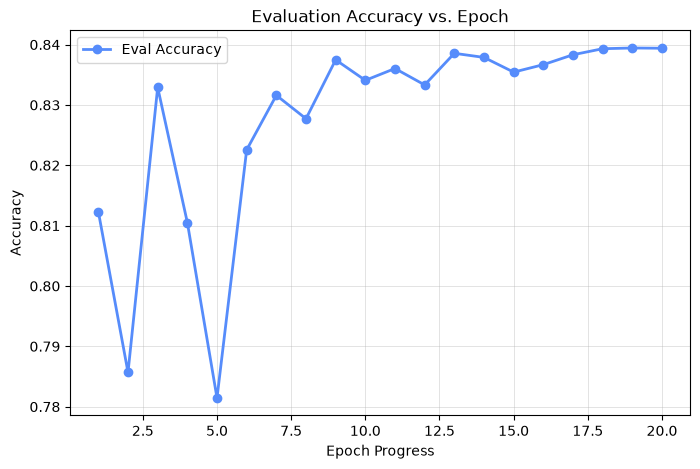

In [15]:
train_output = trainer.train()

In [16]:
# You may add Cells & Code lines if you need
trainer.evaluate()

Training Loss,Validation Loss,Epoch,Accuracy
0.340306,0.366264,20,0.839400


{'eval_loss': 0.366264283657074, 'eval_accuracy': 0.8394}

## SECTION B - Trying dropout

> **Read Section 3.1 of the paper carefully before implementing.**

In [52]:
class FinalAccuracyCallback(TrainerCallback):
    def __init__(self):
        self.final_eval_acc = None

    def on_evaluate(self, args, state, control, metrics, **kwargs):
        if "eval_accuracy" in metrics:
            self.final_eval_acc = metrics["eval_accuracy"]

In [25]:
dropout_rates = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
final_accuracies = []
all_epoch_histories = {}

In [26]:
for p in dropout_rates:
    print(f"\n--- Training DAN (word_dropout = {p}) ---")

    model = DAN(hidden_size=128, word_dropout=p)
    callback = FinalAccuracyCallback()

    trainer = Trainer(
        model=model,
        data_collator=co,
        args=training_args,
        callbacks=[callback],
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    final_accuracies.append(callback.final_eval_acc)


--- Training DAN (word_dropout = 0.0) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.489971,0.427065,0.802480
2,0.399909,0.423769,0.800840
3,0.386562,0.385947,0.828640
4,0.387875,0.427704,0.806040
5,0.378521,0.476789,0.780560
6,0.377448,0.408223,0.820960
7,0.377344,0.379975,0.832600
8,0.366938,0.385098,0.828120
9,0.374854,0.372294,0.836560
10,0.357544,0.373644,0.834480



--- Training DAN (word_dropout = 0.1) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.491680,0.394207,0.825000
2,0.414400,0.425131,0.801400
3,0.394474,0.382566,0.829840
4,0.402838,0.407195,0.813920
5,0.392367,0.483760,0.774200
6,0.386520,0.394489,0.824280
7,0.387553,0.381144,0.832240
8,0.379521,0.380613,0.829920
9,0.385025,0.370863,0.835720
10,0.369583,0.373387,0.837400



--- Training DAN (word_dropout = 0.2) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.496126,0.395749,0.823640
2,0.421197,0.439873,0.790080
3,0.409499,0.380273,0.832120
4,0.415186,0.413551,0.809240
5,0.402923,0.464607,0.782720
6,0.394421,0.416232,0.809680
7,0.397545,0.379137,0.832320
8,0.390276,0.377398,0.831600
9,0.396570,0.370287,0.837800
10,0.380799,0.369974,0.836360


... (2 outputs left out)


--- Training DAN (word_dropout = 0.4) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.514578,0.406458,0.817120
2,0.447992,0.415463,0.810720
3,0.435536,0.411761,0.812080
4,0.438762,0.393747,0.827400
5,0.429532,0.445015,0.789120
6,0.422564,0.403541,0.815040
7,0.429129,0.379885,0.830240
8,0.418623,0.384370,0.828280
9,0.424212,0.372123,0.836520
10,0.409390,0.380530,0.834160



--- Training DAN (word_dropout = 0.5) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.527598,0.407355,0.818120
2,0.459937,0.417629,0.816240
3,0.456646,0.396647,0.828640
4,0.459372,0.402199,0.820600
5,0.450495,0.446975,0.786040
6,0.445170,0.405777,0.813240
7,0.447167,0.386849,0.826080
8,0.437417,0.392742,0.823800
9,0.443623,0.378979,0.833760
10,0.428920,0.385120,0.833520


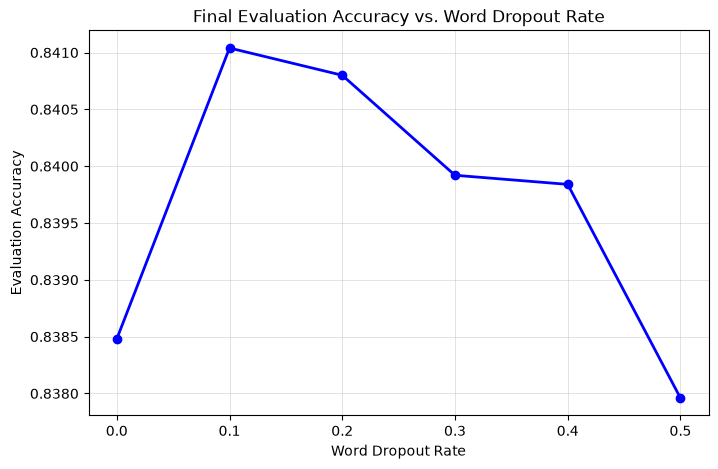

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(dropout_rates, final_accuracies, marker='o', color='b', linewidth=2)
plt.title('Final Evaluation Accuracy vs. Word Dropout Rate')
plt.xlabel('Word Dropout Rate')
plt.ylabel('Evaluation Accuracy')
plt.grid(True)
plt.show()

## SECTION C - Different Layer numbers

In [50]:
layer_counts = [0, 1, 2, 3]
final_accuracies = []

In [53]:
for n in layer_counts:
    print(f"\n--- Training DAN (num_hidden = {n}) ---")

    model = DAN(hidden_size=128, word_dropout=0.1, num_hidden=n)
    callback = FinalAccuracyCallback()

    trainer = Trainer(
        model=model,
        data_collator=co,
        args=training_args,
        callbacks=[callback],
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    final_accuracies.append(callback.final_eval_acc)


--- Training DAN (num_hidden = 0) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.642326,0.585223,0.728640
2,0.552992,0.539571,0.759200
3,0.527423,0.510930,0.779440
4,0.500407,0.492776,0.787240
5,0.487024,0.480172,0.792720
6,0.470861,0.468460,0.798840
7,0.467404,0.460962,0.801360
8,0.455343,0.454467,0.804520
9,0.453492,0.449675,0.806880
10,0.440960,0.445602,0.807040



--- Training DAN (num_hidden = 1) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.524839,0.412564,0.815640
2,0.408643,0.394263,0.824400
3,0.397628,0.385770,0.828800
4,0.396637,0.381726,0.830640
5,0.387730,0.406851,0.813000
6,0.384275,0.384360,0.827880
7,0.384763,0.380070,0.830920
8,0.376876,0.384993,0.827320
9,0.383854,0.373967,0.834880
10,0.367077,0.377283,0.833520



--- Training DAN (num_hidden = 2) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.491680,0.394207,0.825000
2,0.414400,0.425131,0.801400
3,0.394474,0.382566,0.829840
4,0.402838,0.407195,0.813920
5,0.392367,0.483760,0.774200
6,0.386520,0.394489,0.824280
7,0.387553,0.381144,0.832240
8,0.379521,0.380613,0.829920
9,0.385025,0.370863,0.835720
10,0.369583,0.373387,0.837400



--- Training DAN (num_hidden = 3) ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.490722,0.429800,0.802240
2,0.420101,0.443300,0.789400
3,0.401289,0.384997,0.828840
4,0.403175,0.429557,0.800320
5,0.397878,0.477434,0.778080
6,0.386434,0.391938,0.824960
7,0.389986,0.386273,0.829440
8,0.379964,0.377683,0.831640
9,0.386420,0.370040,0.838000
10,0.371012,0.369700,0.837000


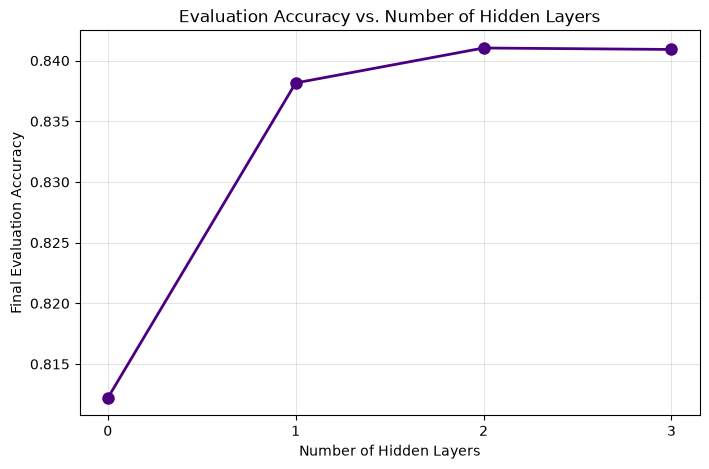

In [54]:
plt.figure(figsize=(8, 5))
plt.plot(layer_counlor='indigo', linewidth=2, markersize=8)
plt.title('Evaluation Accuracy vs. Number of Hidden Layers')
plt.xlabel('Number of Hidden Layers')
plt.ylabel('Final Evaluation Accuracy')
plt.xticks(layer_counts)
plt.grid(True)
plt.show()

## SECTION D - Activations

In [56]:
class AccuracyHistoryCallback(TrainerCallback):
    def __init__(self):
        self.epoch_accuracies = []

    def on_evaluate(self, args, state, control, metrics, **kwargs):
        if "eval_accuracy" in metrics:
            self.epoch_accuracies.append(metrics["eval_accuracy"])

In [57]:
activation_dict = {
    "ReLU": nn.ReLU,
    "GELU": nn.GELU,
    "Tanh": nn.Tanh
}

activation_histories = {}

In [58]:
for name, act_cls in activation_dict.items():
    print(f"\n--- Training DAN with {name} Activation ---")

    model = DAN(hidden_size=128, word_dropout=0.1, num_hidden=2, activation=act_cls)
    callback = AccuracyHistoryCallback()

    trainer = Trainer(
        model=model,
        data_collator=co,
        args=training_args,
        callbacks=[callback],
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        compute_metrics=compute_metrics,
    )

    trainer.train()
    activation_histories[name] = callback.epoch_accuracies


--- Training DAN with ReLU Activation ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.491680,0.394207,0.825000
2,0.414400,0.425131,0.801400
3,0.394474,0.382566,0.829840
4,0.402838,0.407195,0.813920
5,0.392367,0.483760,0.774200
6,0.386520,0.394489,0.824280
7,0.387553,0.381144,0.832240
8,0.379521,0.380613,0.829920
9,0.385025,0.370863,0.835720
10,0.369583,0.373387,0.837400



--- Training DAN with GELU Activation ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.492021,0.394041,0.826960
2,0.415222,0.406341,0.812920
3,0.397208,0.384564,0.829840
4,0.401613,0.382043,0.831880
5,0.391979,0.433570,0.798320
6,0.390625,0.391715,0.825240
7,0.389433,0.382681,0.832520
8,0.383211,0.389744,0.826280
9,0.389778,0.376492,0.835400
10,0.374917,0.377126,0.834840



--- Training DAN with Tanh Activation ---


Epoch,Training Loss,Validation Loss,Accuracy
1,0.479560,0.393232,0.827480
2,0.421743,0.388777,0.828640
3,0.399811,0.386466,0.827840
4,0.404018,0.401625,0.819080
5,0.396565,0.427200,0.802520
6,0.392329,0.390494,0.826600
7,0.391387,0.386018,0.830560
8,0.386306,0.384677,0.829600
9,0.390594,0.379149,0.834040
10,0.378988,0.379931,0.833520


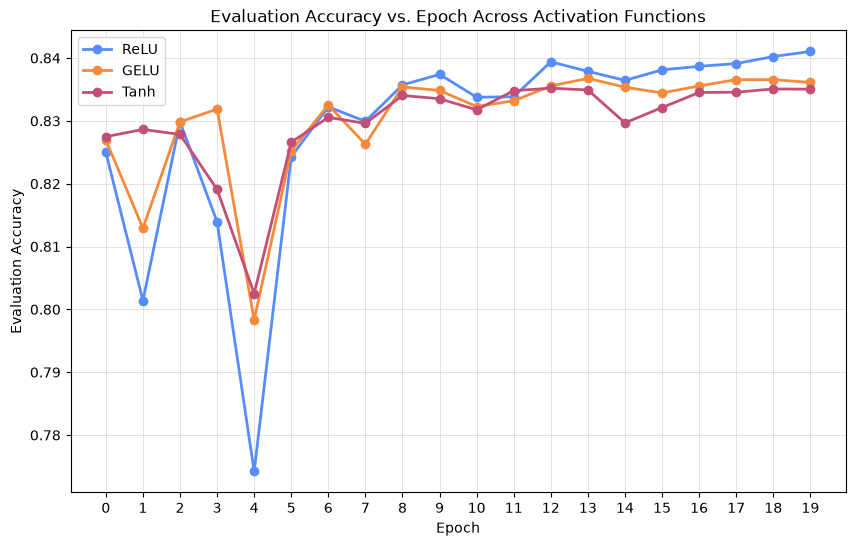

In [60]:
plt.figure(figsize=(10, 6))
epochs = range(20)

for name, histories in activation_histories.items():
    plt.plot(epochs, histories, marker='o', label=name, linewidth=2)

plt.title('Evaluation Accuracy vs. Epoch Across Activation Functions')
plt.xlabel('Epoch')
plt.ylabel('Evaluation Accuracy')
plt.xticks(epochs)
plt.legend()
plt.grid(True)
plt.show()

## SECTION E - Sample 5 Misclassified Examples

Using your **top-performing** model from parts (a)–(d), find five movie reviews from the evaluation set that the model classified incorrectly. For each review, include a short explanation in your report describing why the model likely failed (See section 5.2 of the paper).

> `eval_dataset` was shuffled, so make sure you read the review text from the right source.

In [61]:
best_model = DAN(hidden_size=128, word_dropout=0.1, num_hidden=2, activation=nn.ReLU)

trainer = Trainer(
    model=model,
    data_collator=co,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.390065,0.384154,0.831840
2,0.391611,0.386463,0.826480
3,0.386029,0.379167,0.831840
4,0.389325,0.376773,0.833320
5,0.382319,0.408371,0.813680
6,0.380852,0.388517,0.828600
7,0.381288,0.383284,0.830760
8,0.376937,0.388853,0.828320
9,0.382749,0.377253,0.833520
10,0.367677,0.380421,0.831240


TrainOutput(global_step=15640, training_loss=0.37670261890382106, metrics={'train_runtime': 343.6023, 'train_samples_per_second': 1455.171, 'train_steps_per_second': 45.518, 'total_flos': 0.0, 'train_loss': 0.37670261890382106, 'epoch': 20.0})

In [64]:
eval_output = trainer.predict(eval_dataset)

logits = eval_output.predictions
predicted_labels = np.argmax(logits, axis=-1)
true_labels = eval_output.label_ids

misclassified_indices = np.where(predicted_labels != true_labels)[0]


In [66]:
print(f"Total misclassified: {len(misclassified_indices)} out of {len(eval_dataset)}\n")

Total misclassified: 4133 out of 25000



In [67]:
sample = eval_dataset[misclassified_indices[0]]

In [69]:
label_names = {0: "Negative", 1: "Positive"}

In [70]:
for i, idx in enumerate(misclassified_indices[:5]):
    sample = eval_dataset[int(idx)]

    print(f"=== Misclassified Example {i + 1} (Dataset Index {idx}) ===")
    print(f"True Label:      {label_names[sample['labels']]}")
    print(f"Predicted Label: {label_names[predicted_labels[idx]]}")
    print(f"Review Text:\n{sample['text']}\n")
    print("-" * 60)

=== Misclassified Example 1 (Dataset Index 1) ===
True Label:      Positive
Predicted Label: Negative
Review Text:
This is the latest entry in the long series of films with the French agent, O.S.S. 117 (the French answer to James Bond). The series was launched in the early 1950's, and spawned at least eight films (none of which was ever released in the U.S.). 'O.S.S.117:Cairo,Nest Of Spies' is a breezy little comedy that should not...repeat NOT, be taken too seriously. Our protagonist finds himself in the middle of a spy chase in Egypt (with Morroco doing stand in for Egypt) to find out about a long lost friend. What follows is the standard James Bond/Inspector Cloussou kind of antics. Although our man is something of an overt xenophobe,sexist,homophobe, it's treated as pure farce (as I said, don't take it too seriously). Although there is a bit of rough language & cartoon violence, it's basically okay for older kids (ages 12 & up). As previously stated in the subject line, just sit ba

# SECTION F — Your embeddings vs. GloVe

Use your own Q2 word2vec embeddings, using the same architecture and the given hyperparameters. Bring in `word2vec_vectors.npy` and `word2vec_vocab.json` the same way as the GloVe files in Embeddings Setup, then run the cells below in order.

In [75]:
EMBEDDINGS_PATH = "word2vec_vectors.npy"
VOCAB_PATH = "word2vec_vocab.json"

with open(VOCAB_PATH) as f:
    vocab = json.load(f)

unk_idx = vocab["unk"]

train_dataset = raw_datasets["train"].shuffle(seed=42).map(tokenize_function, batched=True)
eval_dataset = raw_datasets["test"].shuffle(seed=42).map(tokenize_function, batched=True)

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

{'loss': '0.6937', 'grad_norm': '0.1603', 'learning_rate': '0.001915', 'epoch': '0.6394'}
{'eval_loss': '0.6936', 'eval_accuracy': '0.5', 'eval_runtime': '3.04', 'eval_samples_per_second': '8223', 'eval_steps_per_second': '257.2', 'epoch': '1'}
{'loss': '0.6934', 'grad_norm': '0.1656', 'learning_rate': '0.00183', 'epoch': '1.279'}
{'loss': '0.6933', 'grad_norm': '0.1229', 'learning_rate': '0.001744', 'epoch': '1.918'}
{'eval_loss': '0.6935', 'eval_accuracy': '0.5', 'eval_runtime': '2.822', 'eval_samples_per_second': '8859', 'eval_steps_per_second': '277.1', 'epoch': '2'}
{'loss': '0.6934', 'grad_norm': '0.05345', 'learning_rate': '0.001659', 'epoch': '2.558'}
{'eval_loss': '0.6932', 'eval_accuracy': '0.5', 'eval_runtime': '5.8', 'eval_samples_per_second': '4310', 'eval_steps_per_second': '134.8', 'epoch': '3'}
{'loss': '0.6934', 'grad_norm': '0.04317', 'learning_rate': '0.001574', 'epoch': '3.197'}
{'loss': '0.6933', 'grad_norm': '0.004308', 'learning_rate': '0.001489', 'epoch': '3.836

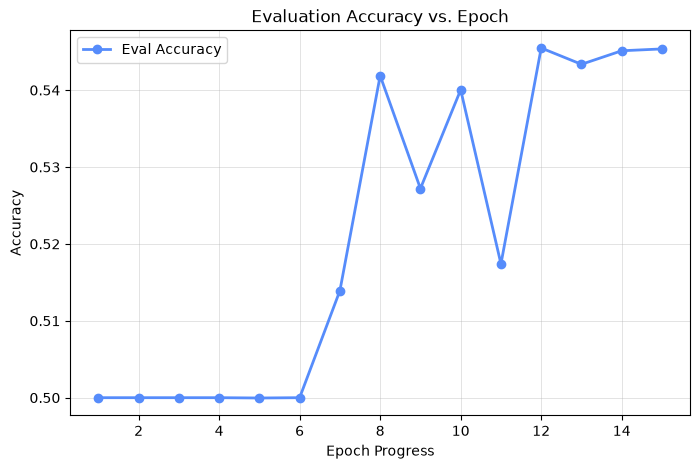

TrainOutput(global_step=11730, training_loss=0.6917594317788257, metrics={'train_runtime': 264.8171, 'train_samples_per_second': 1416.072, 'train_steps_per_second': 44.295, 'train_loss': 0.6917594317788257, 'epoch': 15.0})

In [77]:
# Train a new model.
# YOUR CODE HERE
word2vec_model = DAN(hidden_size=32, word_dropout=0.0, num_hidden=3, activation=nn.ReLU, embedding_path=EMBEDDINGS_PATH)

training_args = TrainingArguments("DAN",
                                  # YOUR CODE HERE
                                  num_train_epochs=15 , #must be at least 10.
                                  per_device_train_batch_size=32,
                                  per_device_eval_batch_size=32,
                                  learning_rate=2e-3,
                                  # END YOUR CODE

                                  save_total_limit=2,
                                  log_level="error",
                                  eval_strategy="epoch")

trainer = Trainer(
    model=word2vec_model,
    data_collator=co,
    args=training_args,
    callbacks = [PlotAccuracyCallback()],
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=compute_metrics,
)

trainer.train()
# END YOUR CODE